Final Weights: [ 0.51193225 -0.26610223]
Final Bias: -0.30000000000000004
Errors per Epoch: [16, 11, 7, 11, 10, 10, 12, 10, 12, 10, 8, 10, 10, 10, 12, 10, 8, 10, 10, 12, 8, 10, 12, 8, 10, 12, 8, 12, 12, 8, 13, 7, 8, 9, 10, 8, 8, 13, 12, 12, 14, 9, 9, 8, 13, 9, 10, 10, 10, 10]


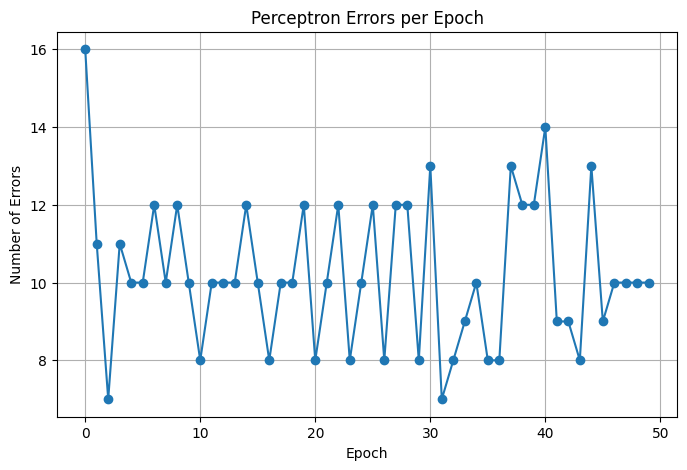

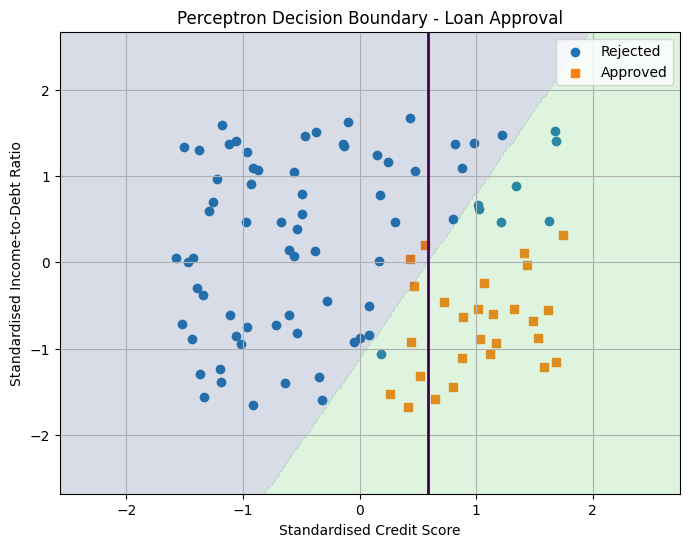


XOR Final Weights: [-0.1  0. ]
XOR Final Bias: 0.0

XOR Predictions:
[0 0] -> 1
[0 1] -> 1
[1 0] -> 0
[1 1] -> 0

XOR Errors per Epoch: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


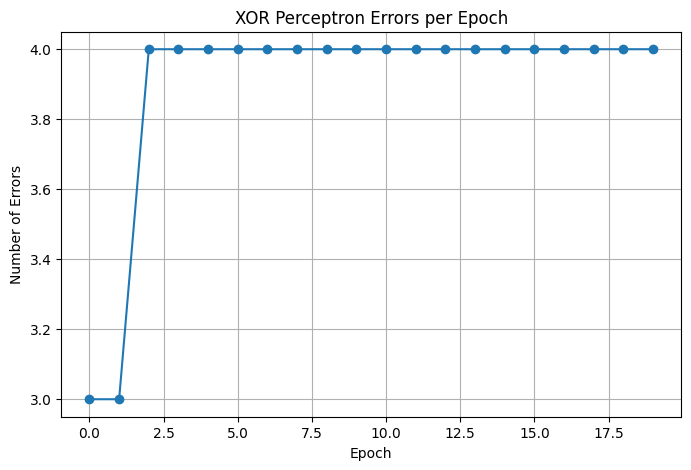

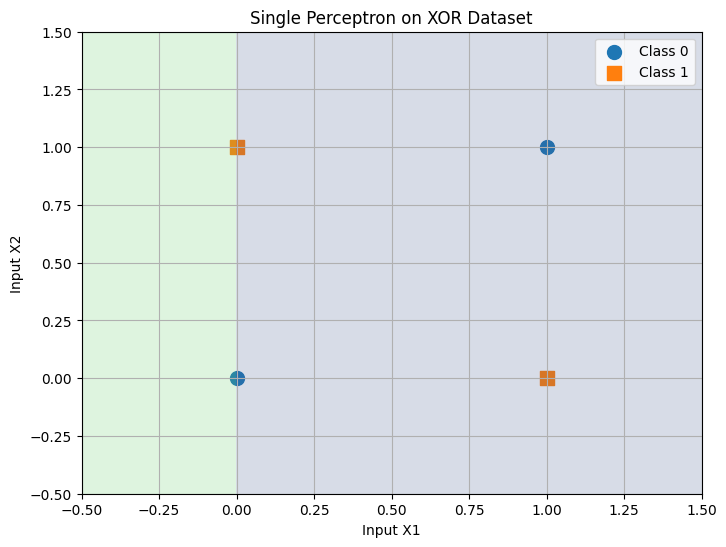


Activation Function Comparison
Input   Step   Sigmoid   ReLU
-3     0     0.047     0
-2     0     0.119     0
-1     0     0.269     0
0     1     0.5     0
1     1     0.731     1
2     1     0.881     2
3     1     0.953     3


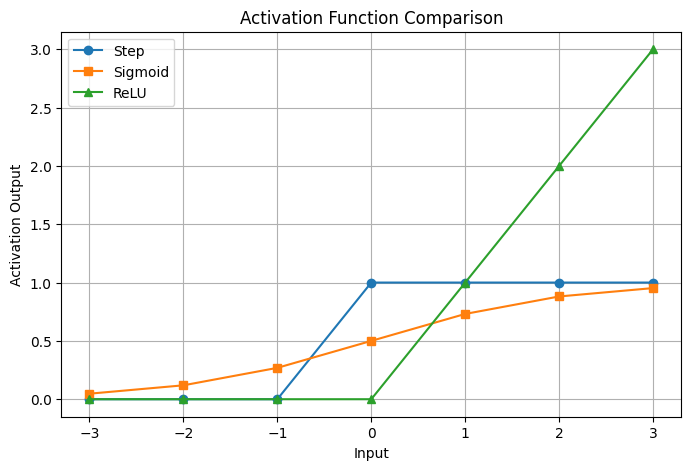


Experiment 7 Completed Successfully!


In [10]:
# EXPERIMENT 7: PERCEPTRON AND FORWARD PROPAGATION

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# --------------------------------------------------
# TASK 1: WEIGHTED SUM, BIAS AND STEP ACTIVATION
# --------------------------------------------------

def step_activation(z):
    return np.where(z >= 0, 1, 0)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def relu(z):
    return np.maximum(0, z)

def forward(x, weights, bias):
    z = np.dot(x, weights) + bias
    return z, step_activation(z)

# --------------------------------------------------
# TASK 2: GENERATE LOAN APPLICATION DATA
# --------------------------------------------------

# 100 applications: credit score and income-to-debt ratio

credit_score = np.random.uniform(300, 850, 100)
debt_ratio = np.random.uniform(0, 1, 100)

X = np.column_stack((credit_score, debt_ratio))

# Label rule: approve if credit score is high
# and income-to-debt ratio is low

y = ((credit_score >= 600) & (debt_ratio <= 0.6)).astype(int)

# Standardise inputs
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)

X = (X - X_mean) / X_std

# --------------------------------------------------
# PERCEPTRON TRAINING
# --------------------------------------------------

weights = np.zeros(2)
bias = 0.0
learning_rate = 0.1
epochs = 50

errors_per_epoch = []
weight_history = []
bias_history = []

for epoch in range(epochs):

    errors = 0

    for i in range(len(X)):

        z = np.dot(X[i], weights) + bias
        prediction = step_activation(z)

        error = y[i] - prediction

        if error != 0:

            weights += learning_rate * error * X[i]
            bias += learning_rate * error

            errors += 1

        weight_history.append(weights.copy())
        bias_history.append(bias)

    errors_per_epoch.append(errors)

print("Final Weights:", weights)
print("Final Bias:", bias)
print("Errors per Epoch:", errors_per_epoch)

# --------------------------------------------------
# TASK 2: PLOT WEIGHT UPDATES / ERRORS PER EPOCH
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(errors_per_epoch, marker='o')

plt.title("Perceptron Errors per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Number of Errors")
plt.grid()
plt.show()

# --------------------------------------------------
# TASK 3: PLOT LEARNED DECISION BOUNDARY
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(X[y == 0, 0], X[y == 0, 1],
            label="Rejected", marker='o')

plt.scatter(X[y == 1, 0], X[y == 1, 1],
            label="Approved", marker='s')

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

Z = step_activation(weights[0]*xx + weights[1]*yy + bias)

plt.contourf(xx, yy, Z, alpha=0.2, levels=[-0.5, 0.5, 1.5])

if abs(weights[1]) > 1e-10:
    boundary = -(weights[0]*xx + bias) / weights[1]
    plt.contour(xx, yy, boundary, levels=[0], linewidths=2)

plt.title("Perceptron Decision Boundary - Loan Approval")
plt.xlabel("Standardised Credit Score")
plt.ylabel("Standardised Income-to-Debt Ratio")
plt.legend()
plt.grid()
plt.show()

# --------------------------------------------------
# TASK 4: TRAIN PERCEPTRON ON XOR
# --------------------------------------------------

XOR_X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

XOR_y = np.array([0, 1, 1, 0])

xor_weights = np.zeros(2)
xor_bias = 0.0

xor_lr = 0.1
xor_epochs = 20

xor_errors = []

for epoch in range(xor_epochs):

    errors = 0

    for i in range(len(XOR_X)):

        z = np.dot(XOR_X[i], xor_weights) + xor_bias
        prediction = step_activation(z)

        error = XOR_y[i] - prediction

        if error != 0:

            xor_weights += xor_lr * error * XOR_X[i]
            xor_bias += xor_lr * error

            errors += 1

    xor_errors.append(errors)

print("\nXOR Final Weights:", xor_weights)
print("XOR Final Bias:", xor_bias)

print("\nXOR Predictions:")

for x in XOR_X:
    z = np.dot(x, xor_weights) + xor_bias
    print(x, "->", step_activation(z))

print("\nXOR Errors per Epoch:", xor_errors)

# --------------------------------------------------
# TASK 4: PLOT XOR TRAINING ERRORS
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(xor_errors, marker='o')

plt.title("XOR Perceptron Errors per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Number of Errors")
plt.grid()
plt.show()

# --------------------------------------------------
# TASK 4: VISUALISE XOR DECISION BOUNDARY
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(XOR_X[XOR_y == 0, 0],
            XOR_X[XOR_y == 0, 1],
            label="Class 0", marker='o', s=100)

plt.scatter(XOR_X[XOR_y == 1, 0],
            XOR_X[XOR_y == 1, 1],
            label="Class 1", marker='s', s=100)

xx, yy = np.meshgrid(
    np.linspace(-0.5, 1.5, 200),
    np.linspace(-0.5, 1.5, 200)
)

Z = step_activation(xor_weights[0]*xx +
                    xor_weights[1]*yy + xor_bias)

plt.contourf(xx, yy, Z, alpha=0.2, levels=[-0.5, 0.5, 1.5])

if abs(xor_weights[1]) > 1e-10:
    boundary = -(xor_weights[0]*xx + xor_bias) / xor_weights[1]
    plt.contour(xx, yy, boundary, levels=[0], linewidths=2)

plt.title("Single Perceptron on XOR Dataset")
plt.xlabel("Input X1")
plt.ylabel("Input X2")
plt.legend()
plt.grid()
plt.show()

# --------------------------------------------------
# TASK 5: COMPARE STEP, SIGMOID AND RELU ACTIVATIONS
# --------------------------------------------------

inputs = np.array([-3, -2, -1, 0, 1, 2, 3])

step_output = step_activation(inputs)
sigmoid_output = sigmoid(inputs)
relu_output = relu(inputs)

print("\nActivation Function Comparison")
print("Input   Step   Sigmoid   ReLU")

for i in range(len(inputs)):
    print(inputs[i], "   ", step_output[i],
          "   ", round(sigmoid_output[i], 3),
          "   ", relu_output[i])

plt.figure(figsize=(8, 5))

plt.plot(inputs, step_output, marker='o', label='Step')
plt.plot(inputs, sigmoid_output, marker='s', label='Sigmoid')
plt.plot(inputs, relu_output, marker='^', label='ReLU')

plt.title("Activation Function Comparison")
plt.xlabel("Input")
plt.ylabel("Activation Output")
plt.legend()
plt.grid()
plt.show()

# --------------------------------------------------
# FINAL RESULT
# --------------------------------------------------

print("\nExperiment 7 Completed Successfully!")